# Predicting Subscription Renewal Risk and Customer Churn Using Machine Learning

**Notebook 02 — Model Evaluation, Testing, and Interpretation**  
**Author:** Trilok Reddy Arava  
**Program:** UC Berkeley Professional Certificate in Machine Learning and Artificial Intelligence  
**Assignment:** Final Capstone 24.1

**Purpose (following the Berkeley `CapstoneEvaluation` example):** Repeat essential data setup, load the selected model, report final performance and confusion matrix, test individual customer predictions, interpret model weights and feature importance, examine local explanations, and conclude with business insights and future research.

**Run order:** Run [Notebook 01](Subscription_Churn_Prediction.ipynb) first, because it generates the tuned-model files and comparison reports in `outputs/reports/`. Then restart and run this notebook from top to bottom.


## 1. Setup and Data Preparation

This evaluation notebook reuses the **same data preparation, stratified 80/20 train/test split, and trained model artifacts** generated by Notebook 01. It does not rerun hyperparameter tuning or use the held-out test set to choose a model.

**Two setup stages:** The first code cell loads the saved cross-validation results, held-out predictions, and selected-model name so that evaluation can begin immediately. Later, under **Section 4 — Model Interpretation**, the notebook reconstructs the same cleaned feature matrix and held-out split, then loads the fitted model from disk. That later setup is necessary for permutation importance and customer-level explanations. It is intentionally kept immediately before the code that first needs `X_test` and `model`, preserving the existing execution order.

For the supplied data and training configuration, the expected selected classifier is **Logistic Regression**; the notebook reads the actual selection from the saved report rather than hard-coding it.

## 2. Model Evaluation

### 2.1 Cross-Validation Selection and Performance Comparison

Review the training-only cross-validation results and held-out performance metrics for **all five classifiers**. The selected model is determined by the saved training cross-validation results, not by the held-out test set. This section provides the overall evaluation summary; the next section examines the selected model's test predictions in more detail.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns,joblib
from IPython.display import display
from sklearn.metrics import precision_recall_curve, confusion_matrix, classification_report, average_precision_score
from sklearn.inspection import permutation_importance
ROOT=Path.cwd() if (Path.cwd()/'data'/'Telco-Customer-Churn.csv').exists() else Path.cwd().parent
REPORT=ROOT/'outputs'/'reports';FIG=ROOT/'outputs'/'figures'
cv=pd.read_csv(REPORT/'cross_validation_results.csv');test=pd.read_csv(REPORT/'final_model_comparison.csv');pred=pd.read_csv(REPORT/'test_predictions.csv')
selected=(REPORT/'selected_model.txt').read_text().strip()
print('Selected using training-only cross-validation:',selected)
display(cv.round(4));display(test.round(4))
selected_pred=pred[pred.model==selected].copy()
print('Selected model confusion matrix at 0.50 threshold:')
print(confusion_matrix(selected_pred.actual,selected_pred.prediction_0_5))
print(classification_report(selected_pred.actual,selected_pred.prediction_0_5,target_names=['No churn','Churn']))

Selected using training-only cross-validation: Logistic Regression


,model,cv_average_precision,cv_roc_auc,cv_recall,cv_f1,best_params
0,Logistic Regression,0.6602,0.8458,0.5445,0.5945,"{'classifier__C': 1, 'classifier__class_weight..."
1,Random Forest,0.6526,0.8433,0.4702,0.5554,"{'classifier__class_weight': None, 'classifier..."
2,Support Vector Classifier,0.6494,0.8342,0.5171,0.5817,"{'classifier__estimator__C': 0.1, 'classifier_..."
3,Naive Bayes,0.6134,0.8202,0.8462,0.5979,{'classifier__var_smoothing': 1e-09}
4,Decision Tree,0.5903,0.8012,0.5244,0.5584,"{'classifier__class_weight': None, 'classifier..."


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Random Forest,0.7999,0.6691,0.4866,0.5635,0.8394,0.6502
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419,0.6334
2,Support Vector Classifier,0.7949,0.6421,0.5134,0.5706,0.8266,0.6211
3,Decision Tree,0.7793,0.5782,0.6230,0.5997,0.8048,0.6026
4,Naive Bayes,0.6927,0.4567,0.8316,0.5896,0.8070,0.5846


Selected model confusion matrix at 0.50 threshold:
[[926 109]
 [165 209]]
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## 3. Model Testing

### 3.1 Held-Out Test Predictions and Confusion Matrix

Test the selected classifier on the original held-out test split using the predictions saved by Notebook 01. The confusion matrix counts true negatives, false positives, false negatives, and true positives at the prespecified 0.50 decision threshold. The test data are **not** used to select or retune the model.

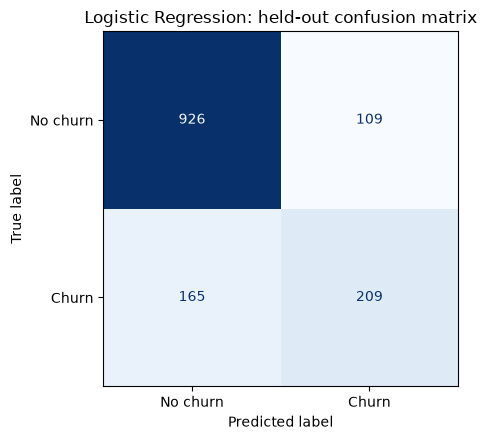

,selected_model,accuracy,precision,recall,f1
0,Logistic Regression,0.8055,0.6572,0.5588,0.604


In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from IPython.display import display
cm = confusion_matrix(selected_pred.actual, selected_pred.prediction_0_5)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['No churn', 'Churn']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'{selected}: held-out confusion matrix')
fig.tight_layout()
fig.savefig(FIG / 'final_selected_model_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
summary = pd.DataFrame([{'selected_model': selected, 'accuracy': accuracy_score(selected_pred.actual, selected_pred.prediction_0_5), 'precision': precision_score(selected_pred.actual, selected_pred.prediction_0_5, zero_division=0), 'recall': recall_score(selected_pred.actual, selected_pred.prediction_0_5), 'f1': f1_score(selected_pred.actual, selected_pred.prediction_0_5)}])
display(summary.round(4))


### 3.2 Precision–Recall and Classification Threshold Diagnostics

Examine how precision and recall vary with the classification threshold on the held-out sample. These are **illustrative test-set diagnostics only**. Any operational threshold must be chosen using separate training/validation predictions and explicit business costs or outreach capacity; it must not be optimized on the test set.

,threshold,customers_flagged,precision,recall,f1
0,0.3,543,0.519,0.754,0.615
1,0.4,440,0.568,0.668,0.614
2,0.5,318,0.657,0.559,0.604
3,0.6,210,0.714,0.401,0.514


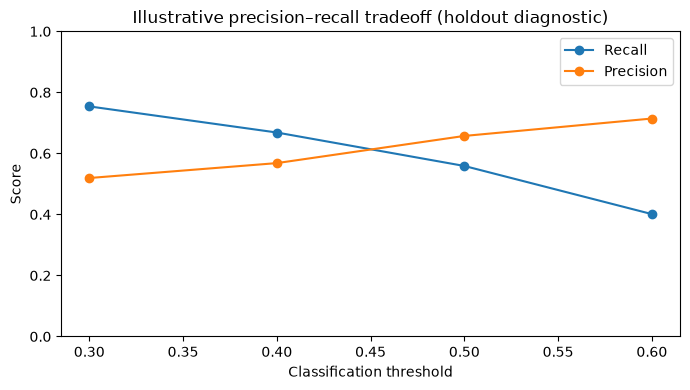

In [3]:
# Illustrate threshold tradeoffs on the holdout set without using this set to choose a deployment threshold.
# The 0.50 threshold remains the prespecified comparison point; future operational thresholds require validation data.
rows=[]
for t in [0.30,0.40,0.50,0.60]:
    y=selected_pred.actual.to_numpy();p=(selected_pred.probability.to_numpy()>=t).astype(int)
    from sklearn.metrics import precision_score,recall_score,f1_score
    rows.append({'threshold':t,'customers_flagged':int(p.sum()),'precision':precision_score(y,p,zero_division=0),'recall':recall_score(y,p,zero_division=0),'f1':f1_score(y,p,zero_division=0)})
threshold_table=pd.DataFrame(rows);display(threshold_table.round(3));threshold_table.to_csv(REPORT/'illustrative_threshold_tradeoffs.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(threshold_table.threshold,threshold_table.recall,marker='o',label='Recall');ax.plot(threshold_table.threshold,threshold_table.precision,marker='o',label='Precision');ax.set(xlabel='Classification threshold',ylabel='Score',title='Illustrative precision–recall tradeoff (holdout diagnostic)',ylim=(0,1));ax.legend();fig.tight_layout();fig.savefig(FIG/'11_threshold_tradeoff.png',dpi=150);plt.show()

## 4. Model Interpretation

### 4.1 Reconstructing Model Inputs and Global Permutation Importance

**Reconstructing model inputs:** The following code reloads the original customer data, applies the same numeric conversion and engineered features used in Notebook 01, reconstructs the original held-out split, and loads the saved selected model. These objects are required for the interpretation and individual-customer analyses that follow; **no model is refitted**.

**Global interpretation:** Permutation importance measures the decrease in average precision when a feature is shuffled on the held-out sample. It describes model reliance, **not causality**. It is presented as a final descriptive analysis and is not used to retune the model or select features.

,feature,importance_mean,importance_std
4,tenure,0.2371,0.0064
7,InternetService,0.0815,0.0193
17,MonthlyCharges,0.0675,0.0182
14,Contract,0.0391,0.0048
18,TotalCharges,0.0282,0.0083
11,TechSupport,0.0153,0.0044
8,OnlineSecurity,0.0106,0.0034
13,StreamingMovies,0.0093,0.0107
19,AddOnServiceCount,0.0061,0.0045
16,PaymentMethod,0.0059,0.0063


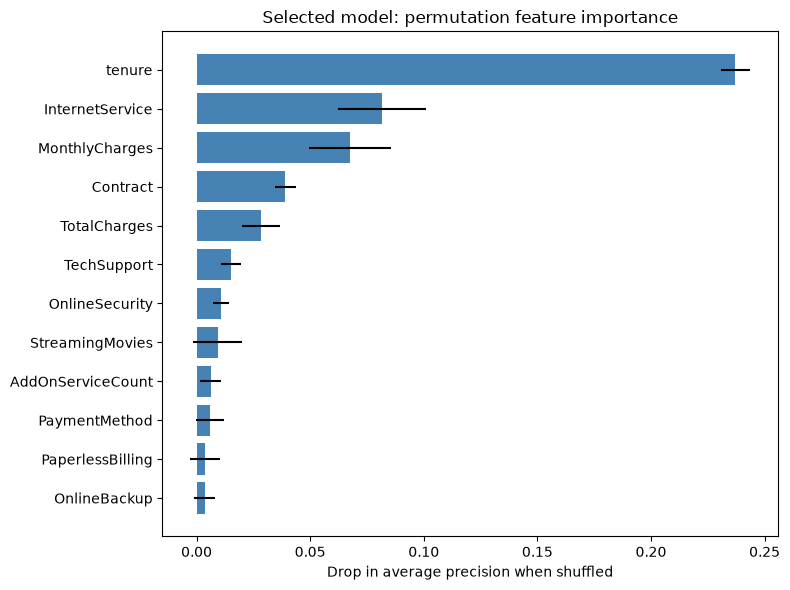

In [4]:
# Reconstruct original modeling inputs for permutation importance on the held-out set.
from sklearn.model_selection import train_test_split
import sys
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from capstone_utils import to_dense
raw=pd.read_csv(ROOT/'data'/'Telco-Customer-Churn.csv').drop_duplicates(subset='customerID').copy()
raw['TotalCharges']=pd.to_numeric(raw['TotalCharges'].replace(r'^\s*$',np.nan,regex=True),errors='coerce')
raw['ChurnFlag']=raw['Churn'].map({'No':0,'Yes':1}).astype(int)
raw['TenureGroup']=pd.cut(raw['tenure'],bins=[-1,12,24,48,72],labels=['0-12 months','13-24 months','25-48 months','49-72 months'])
raw['MonthlyChargeBand']=pd.cut(raw['MonthlyCharges'],bins=[-np.inf,35,70,np.inf],labels=['Under $35','$35-$70','Over $70'])
service_cols=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
raw['AddOnServiceCount']=raw[service_cols].eq('Yes').sum(axis=1)
X=raw.drop(columns=['customerID','Churn','ChurnFlag','TenureGroup','MonthlyChargeBand']);y=raw['ChurnFlag']
_,X_test,_,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=42)
model=joblib.load(REPORT/('model_'+selected.lower().replace(' ','_')+'.joblib'))
pi=permutation_importance(model,X_test,y_test,n_repeats=5,random_state=42,scoring='average_precision',n_jobs=1)
imp=pd.DataFrame({'feature':X_test.columns,'importance_mean':pi.importances_mean,'importance_std':pi.importances_std}).sort_values('importance_mean',ascending=False)
imp.to_csv(REPORT/'final_permutation_importance.csv',index=False)
display(imp.head(12).round(4))
fig,ax=plt.subplots(figsize=(8,6));top=imp.head(12).iloc[::-1];ax.barh(top.feature,top.importance_mean,xerr=top.importance_std,color='steelblue');ax.set(xlabel='Drop in average precision when shuffled',title='Selected model: permutation feature importance');fig.tight_layout();fig.savefig(FIG/'12_final_feature_importance.png',dpi=150,bbox_inches='tight');plt.show()

### 4.2 Logistic Regression Coefficients — Global Model Interpretation

The selected model's one-hot encoded and scaled coefficients show the direction and relative size of **model associations** with churn. Positive coefficients increase the model's estimated log-odds of churn, holding its other encoded inputs fixed; negative coefficients decrease them. Because correlated inputs and one-hot categories complicate interpretation, these are **not causal effects**. Permutation importance above complements coefficient analysis.


,encoded_feature,coefficient,absolute_coefficient
1,num__tenure,-1.2397,1.2397
39,cat__Contract_Two year,-0.7741,0.7741
16,cat__InternetService_DSL,-0.6840,0.6840
17,cat__InternetService_Fiber optic,0.6467,0.6467
2,num__MonthlyCharges,-0.6414,0.6414
37,cat__Contract_Month-to-month,0.5786,0.5786
3,num__TotalCharges,0.5149,0.5149
40,cat__PaperlessBilling_No,-0.3448,0.3448
35,cat__StreamingMovies_No internet service,-0.2805,0.2805
32,cat__StreamingTV_No internet service,-0.2805,0.2805


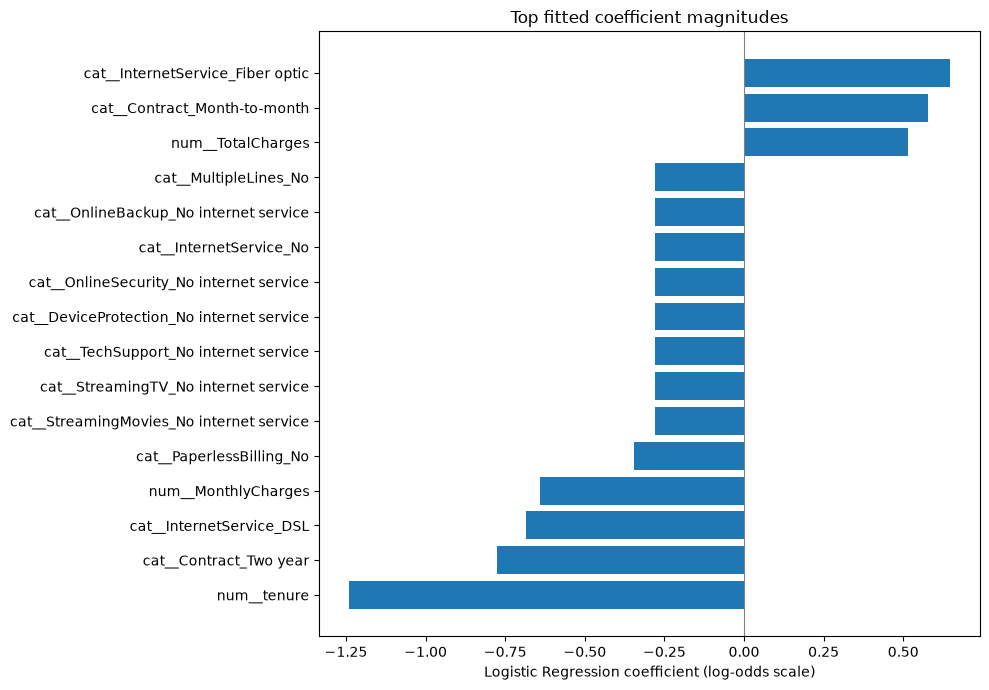

In [5]:
# Explain the fitted, cross-validated Logistic Regression model (no refitting on test data).
if selected != 'Logistic Regression':
    print(f'Note: selected model is {selected}; Logistic Regression coefficient analysis is skipped.')
else:
    fitted_preprocessor = model.named_steps['preprocessor']
    names = fitted_preprocessor.get_feature_names_out()
    weights = model.named_steps['classifier'].coef_[0]
    coefficient_table = pd.DataFrame({'encoded_feature': names, 'coefficient': weights})
    coefficient_table['absolute_coefficient'] = coefficient_table['coefficient'].abs()
    coefficient_table = coefficient_table.sort_values('absolute_coefficient', ascending=False)
    display(coefficient_table.head(20).round(4))
    coefficient_table.to_csv(REPORT / 'selected_logistic_regression_coefficients.csv', index=False)
    top = coefficient_table.head(16).sort_values('coefficient')
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top['encoded_feature'], top['coefficient'])
    ax.axvline(0, color='gray', linewidth=0.8)
    ax.set(xlabel='Logistic Regression coefficient (log-odds scale)', title='Top fitted coefficient magnitudes')
    fig.tight_layout()
    fig.savefig(FIG / 'selected_logistic_regression_coefficients.png', dpi=150, bbox_inches='tight')
    plt.show()


### 4.3 Understanding and Validating Explanations

The coefficient and permutation-importance analyses above are **global explanations** of model behavior. Sections 4.4–4.6 below also show **individual customer predictions**, a retrospective risk-prioritization example, and **local one-variable sensitivity checks**. The local sensitivity checks are not SHAP or LIME explanations, and they do not establish causal effects.

Explanations should ultimately be tested for stability across resamples, time periods, and customer segments. Permutation importance on a single held-out sample is descriptive and has not been independently validated on another dataset.

### 4.4 Individual Customer Churn Probability — Practical Demonstration

Sample Project 2 demonstrates individual equipment predictions. Here we adapt the idea to **illustrative customer-level churn risk** using the selected model and a few rows from the original held-out test set. The table uses artificial case labels, not customer IDs. Probabilities are model estimates, not observed cancellation certainty. No outreach decisions are made here.

In [6]:
# Use the model and X_test reconstructed above; do not fit on held-out records.
example_probabilities = model.predict_proba(X_test)[:, 1]
case_order = np.argsort(example_probabilities)
chosen_positions = [int(case_order[0]), int(case_order[len(case_order)//2]), int(case_order[-1])]
example_cols = ['tenure', 'Contract', 'InternetService', 'MonthlyCharges', 'PaymentMethod']
examples = X_test.iloc[chosen_positions][example_cols].reset_index(drop=True).copy()
examples.insert(0, 'example_case', ['Example A (lower score)', 'Example B (middle score)', 'Example C (higher score)'])
examples['predicted_churn_probability'] = np.round(example_probabilities[chosen_positions], 4)
examples['predicted_churn_at_0_50'] = np.where(example_probabilities[chosen_positions] >= 0.5, 'Churn', 'No churn')
display(examples)
examples.to_csv(REPORT/'illustrative_customer_risk_examples.csv', index=False)
print('These are three held-out example rows, not real customer outreach recommendations.')

,example_case,tenure,Contract,InternetService,MonthlyCharges,PaymentMethod,predicted_churn_probability,predicted_churn_at_0_50
0,Example A (lower score),72,Two year,No,19.95,Bank transfer (automatic),0.0017,No churn
1,Example B (middle score),72,One year,Fiber optic,97.25,Credit card (automatic),0.1904,No churn
2,Example C (higher score),1,Month-to-month,Fiber optic,95.10,Electronic check,0.8552,Churn


These are three held-out example rows, not real customer outreach recommendations.


### 4.5 Illustrative Customer-Risk Report and Outreach Capacity

An operational workflow might rank customers by predicted probability and review only the top portion that a customer-success team can realistically contact. The following **retrospective** example reports the highest-scoring 10% of held-out customers, with anonymous case numbers. The observed outcomes are used only for evaluation, not for deciding who to contact. This is not a prospective retention experiment.

In [7]:
risk_report = pd.DataFrame({
    'anonymous_case': ['Holdout-%04d' % (i+1) for i in range(len(X_test))],
    'predicted_churn_probability': example_probabilities,
    'observed_churn_for_retrospective_evaluation': y_test.to_numpy(),
    'tenure_months': X_test['tenure'].to_numpy(),
    'contract_type': X_test['Contract'].to_numpy(),
    'monthly_charges': X_test['MonthlyCharges'].to_numpy()
}).sort_values('predicted_churn_probability', ascending=False).reset_index(drop=True)
capacity = int(np.ceil(0.10 * len(risk_report)))
top_decile = risk_report.head(capacity).copy()
print('Holdout customers:', len(risk_report))
print('Illustrative 10% outreach capacity:', capacity)
print('Observed churn rate among top-ranked cases:', f"{top_decile.observed_churn_for_retrospective_evaluation.mean():.1%}")
print('Overall observed holdout churn rate:', f"{risk_report.observed_churn_for_retrospective_evaluation.mean():.1%}")
display(top_decile.head(10))
top_decile.to_csv(REPORT/'illustrative_top_decile_risk_report.csv', index=False)

Holdout customers: 1409
Illustrative 10% outreach capacity: 141
Observed churn rate among top-ranked cases: 74.5%
Overall observed holdout churn rate: 26.5%


,anonymous_case,predicted_churn_probability,observed_churn_for_retrospective_evaluation,tenure_months,contract_type,monthly_charges
0,Holdout-1091,0.855213,1,1,Month-to-month,95.10
1,Holdout-1222,0.832259,1,1,Month-to-month,95.45
2,Holdout-1176,0.829137,1,7,Month-to-month,99.25
3,Holdout-1165,0.822014,1,7,Month-to-month,101.95
4,Holdout-1110,0.819030,1,1,Month-to-month,85.05
5,Holdout-0890,0.818087,0,2,Month-to-month,84.05
6,Holdout-0648,0.817925,1,3,Month-to-month,100.95
7,Holdout-0628,0.817366,1,3,Month-to-month,96.60
8,Holdout-1139,0.816692,1,3,Month-to-month,105.90
9,Holdout-1356,0.812736,0,4,Month-to-month,83.25


### 4.6 Local Explanations — Individual Prediction Sensitivity Demonstration

Permutation importance above summarizes **global** predictive dependence. For a local, accessible illustration, we compare each example customer's predicted probability against a modified version of the same record with one feature set to a training-set reference value. This is a **one-variable sensitivity check**, not a SHAP explanation, causal effect, or realistic intervention recommendation. Changing contract type or price while holding everything else fixed may describe a combination not commonly observed in real customers.

In [8]:
# Reference values must come from training data, never from the held-out outcomes.
X_train_local, _, _, _ = train_test_split(X, y, test_size=.20, stratify=y, random_state=42)
reference_values = {
    'tenure': float(X_train_local['tenure'].median()),
    'MonthlyCharges': float(X_train_local['MonthlyCharges'].median()),
    'Contract': X_train_local['Contract'].mode().iloc[0],
    'InternetService': X_train_local['InternetService'].mode().iloc[0]
}
sensitivity_rows = []
for case_label, pos in zip(['Example A', 'Example B', 'Example C'], chosen_positions):
    original = X_test.iloc[[pos]].copy()
    original_probability = float(model.predict_proba(original)[0, 1])
    for feature, reference in reference_values.items():
        alternative = original.copy()
        alternative.loc[:, feature] = reference
        alternative_probability = float(model.predict_proba(alternative)[0, 1])
        sensitivity_rows.append({
            'example_case': case_label, 'changed_feature': feature,
            'original_value': str(original.iloc[0][feature]),
            'reference_value_from_training': str(reference),
            'original_probability': original_probability,
            'reference_probability': alternative_probability,
            'probability_difference_original_minus_reference': original_probability-alternative_probability
        })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))
sensitivity.to_csv(REPORT/'illustrative_local_sensitivity.csv', index=False)
print('Sensitivity does not demonstrate causality or justify changing a customer contract.')

,example_case,changed_feature,original_value,reference_value_from_training,original_probability,reference_probability,probability_difference_original_minus_reference
0,Example A,tenure,72,29.0,0.0017,0.0151,-0.0133
1,Example A,MonthlyCharges,19.95,70.5,0.0017,0.0006,0.0011
2,Example A,Contract,Two year,Month-to-month,0.0017,0.0067,-0.0050
3,Example A,InternetService,No,Fiber optic,0.0017,0.0044,-0.0027
4,Example B,tenure,72,29.0,0.1904,0.6731,-0.4827
5,Example B,MonthlyCharges,97.25,70.5,0.1904,0.2935,-0.1032
6,Example B,Contract,One year,Month-to-month,0.1904,0.3216,-0.1312
7,Example B,InternetService,Fiber optic,Fiber optic,0.1904,0.1904,0.0000
8,Example C,tenure,1,29.0,0.8552,0.5898,0.2654
9,Example C,MonthlyCharges,95.1,70.5,0.8552,0.9089,-0.0536


Sensitivity does not demonstrate causality or justify changing a customer contract.


## 5. Overall Business Findings and Recommended Next Steps

**What the EDA supports:** churn is higher among month-to-month customers and several other observed segments. This supports further investigation and outreach prioritization, not causal claims.

**What the model supports:** historical customer characteristics can rank churn risk better than chance on a held-out telecom sample. The chosen model reflects training-only CV selection; review recall and precision together when planning capacity.

**Recommended pilot:** (1) identify high-risk customers using a threshold chosen on a separate validation sample; (2) provide customer-success outreach or onboarding assistance; (3) randomly assign eligible customers to outreach versus business-as-usual; (4) measure incremental retention, cost per retained customer, and customer experience; (5) review data privacy, subgroup fairness, drift, and operational feasibility before deployment.

**Important limitations:** this dataset is telecom rather than SaaS renewal data, contains observational associations, and does not establish the causal effect of discounts, contract changes, or support. No financial uplift is claimed without intervention data.

## 6. Final Conclusion, Business Recommendations, and Future Work

### 6.1 Project Summary and Research Question

The objective of this capstone project was to investigate whether machine learning can identify customers at elevated risk of churn using historical subscription, service, and billing information.

The project was motivated by my professional experience in Customer Subscription and Renewal Management and was conducted using the publicly available IBM Telco Customer Churn dataset to maintain appropriate confidentiality of proprietary company information.

The analysis included exploratory data analysis, data preprocessing, feature engineering, baseline modeling, hyperparameter tuning, and comparative evaluation of five classification algorithms:

- Naive Bayes
- Logistic Regression
- Decision Tree
- Support Vector Classifier
- Random Forest

The results demonstrate that machine learning can identify meaningful patterns associated with customer churn and provide risk estimates that may support customer retention planning.

### 6.2 Final Model Selection and Performance

Logistic Regression was selected as the final model based on training-only cross-validation average precision, balancing predictive performance, interpretability, and practical applicability.

The selected model achieved the following results on the held-out test dataset:

| Metric | Result |
|---|---|
| Accuracy | 80.55% |
| Precision | 65.72% |
| Recall | 55.88% |
| F1-score | 0.6040 |
| ROC-AUC | 0.8419 |
| Average Precision | 0.6334 |

These results suggest that the model can distinguish between customers with different churn risks reasonably well. However, the recall of 55.88% indicates that approximately 44% of actual churners are not identified at the default classification threshold.

This highlights an important business consideration: optimizing overall accuracy alone is insufficient when the objective is to identify customers who may benefit from proactive retention efforts.

### 6.3 Key Business Insights

The exploratory analysis and model interpretation identified several characteristics associated with customer churn:

**Contract type:** Month-to-month customers exhibited substantially higher churn rates than customers with one-year or two-year contracts.

**Customer tenure:** Customers with shorter tenure showed elevated churn risk, suggesting that early customer engagement and onboarding may deserve particular attention.

**Payment method:** Customers using electronic-check payments exhibited higher observed churn rates than those using certain other payment methods.

**Internet service:** Fiber-optic service customers showed higher observed churn rates than DSL customers and customers without internet service.

These findings represent statistical associations within the public telecom dataset and should not be interpreted as evidence that any individual characteristic causes churn.

### 6.4 Business Recommendations

Based on the analysis, the following retention strategies could be evaluated:

1. **Risk-based customer prioritization:** Use predicted churn probabilities to identify customers who may warrant additional customer-success attention, rather than relying solely on broad customer segmentation.

2. **Early lifecycle engagement:** Evaluate enhanced onboarding, proactive check-ins, and service reviews for newer customers and customers with shorter tenure.

3. **Contract renewal engagement:** Investigate whether targeted renewal communications and appropriate contract options can improve engagement among customers with month-to-month agreements.

4. **Service and billing experience:** Examine customer feedback, service quality, and payment-related friction in segments exhibiting higher observed churn.

5. **Operationally appropriate thresholds:** Evaluate alternative prediction thresholds based on retention-team capacity, false-positive costs, and the business impact of missed churners.

These recommendations should be treated as hypotheses for business testing, not proven retention interventions.

### 6.5 Limitations

Several limitations should be considered before applying these findings in a production environment.

- The IBM Telco dataset represents telecommunications customers and is not directly representative of enterprise software subscription renewals.
- The dataset is observational and cross-sectional, limiting causal interpretation and understanding of customer behavior over time.
- Predictive performance was evaluated on historical held-out data, not prospectively validated on future renewal outcomes.
- The model may miss customers who ultimately churn and may incorrectly flag customers who would otherwise remain.
- Fairness, model drift, intervention effectiveness, and operational costs require additional evaluation.

Consequently, the model should be viewed as an academic demonstration of a potential analytical approach rather than a production-ready customer retention solution.

### 6.6 Future Work

Potential future improvements include:

- Evaluating classification thresholds and precision–recall tradeoffs against realistic customer-success outreach capacity.
- Incorporating time-based customer behavior, engagement trends, service interactions, and renewal history where appropriately available.
- Validating model performance on representative subscription renewal data with suitable data governance and privacy safeguards.
- Monitoring predictive performance, calibration, fairness, and data drift over time.
- Conducting controlled retention experiments to measure whether targeted interventions improve actual renewal outcomes.
- Evaluating business-oriented measures such as retained revenue, intervention cost, and return on retention investment.

### 6.7 Final Closing Statement

This capstone demonstrates how machine learning can transform historical customer and subscription information into actionable churn-risk insights.

By comparing multiple classification algorithms and evaluating the selected model through predictive metrics, global interpretation, and individual customer analysis, the project connects technical machine learning methods with a practical subscription management challenge.

**The central takeaway is that predictive modeling can help businesses identify where retention attention may be most valuable, but prediction alone does not guarantee improved customer outcomes.** Real business value depends on responsible deployment, reliable validation, appropriate operational decisions, and measurable retention interventions.

For me, this project also provides an opportunity to apply the machine learning concepts learned throughout the UC Berkeley program to a business problem closely aligned with my professional responsibilities in Customer Subscription and Renewal Management.